# Notebook 02 — Feature Engineering

**Project:** Credit Default Risk Prediction on 30,000 Customer Records  
**Input:** `data/processed/clean.parquet`  
**Output:** `data/processed/features.parquet`

---

### Objectives
Construct domain-driven predictive features across four structured groups matching our project specifications:
1. **Credit-Limit Features:** Monthly utilization ratios (`CREDIT_UTIL_1..6`), `AVG_UTIL`, `MAX_UTIL`, `OVER_LIMIT_MONTHS`, and `LOG_LIMIT_BAL` (noting that `LIMIT_BAL` encompasses both individual consumer and supplementary family credit).
2. **Repayment-History Features:** `MAX_DELAY`, `AVG_DELAY`, `NUM_DELAYED_MONTHS` (`PAY_k >= 1`), `NUM_PAID_FULL_MONTHS` (`PAY_k == -1`), `RECENT_DELAY` (`PAY_1`), `DELAY_TREND` (`PAY_1 - PAY_6`), and `EVER_SEVERE_DELAY` (`any PAY_k >= 3`).
3. **Billing-Statement & Payment Features:** `AVG_BILL`, `MAX_BILL`, `BILL_TREND` (`BILL_AMT1 - BILL_AMT6`), `AVG_PAY_AMT`, `TOTAL_PAY_AMT`, temporally aligned payment-to-bill ratios (`PAY_RATIO_k = PAY_AMT_k / BILL_AMT_{k+1}` clipped to `[0, 1.5]`), `AVG_PAY_RATIO`, `UNPAID_BALANCE`, `UNPAID_TO_LIMIT`, and `log1p` transformations of skewed monetary columns.
4. **Demographic Encodings:** Binary gender indicator (`SEX_FEMALE`), one-hot encoded `EDUCATION` and `MARRIAGE` categories, and age buckets.

> **Leakage Prevention Policy:** All feature transformations in `build_features(df)` are row-wise deterministic functions of a customer's own history and use **zero target or cross-row aggregation statistics**. Feature scaling (`StandardScaler`) is intentionally **not** performed here—it is encapsulated inside the `scikit-learn` `Pipeline` in Notebook 04 and fit strictly on `X_train`.

In [1]:
from pathlib import Path
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR = Path("data/processed")

df_clean = pd.read_parquet(PROCESSED_DIR / "clean.parquet")
print(f"Loaded clean.parquet: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")

Loaded clean.parquet: 30,000 rows x 24 columns


## 1. Reusable Feature Engineering Pipeline (`build_features`)

We encapsulate all feature creation inside `build_features(df)` so the exact same transformation logic can be applied consistently to any data split without target leakage.

In [2]:
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Build credit-limit, repayment-history, billing-statement/payment, and demographic features.
    Row-wise deterministic transformation with zero cross-row or target leakage.
    """
    out = df.copy()
    pay_cols = [f"PAY_{i}" for i in range(1, 7)]
    bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
    pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

    # -------------------------------------------------------------------------
    # A. Credit-Limit Features
    # -------------------------------------------------------------------------
    limit = out["LIMIT_BAL"].astype(float)
    util_cols = []
    for k in range(1, 7):
        u_col = f"CREDIT_UTIL_{k}"
        out[u_col] = out[f"BILL_AMT{k}"] / limit
        util_cols.append(u_col)

    out["AVG_UTIL"] = out[util_cols].mean(axis=1)
    out["MAX_UTIL"] = out[util_cols].max(axis=1)
    out["OVER_LIMIT_MONTHS"] = sum((out[f"BILL_AMT{k}"] > limit).astype(int) for k in range(1, 7))
    out["LOG_LIMIT_BAL"] = np.log1p(np.maximum(0.0, limit))

    # -------------------------------------------------------------------------
    # B. Repayment-History Features (from PAY_1..PAY_6)
    # -------------------------------------------------------------------------
    pay_mat = out[pay_cols]
    out["MAX_DELAY"] = pay_mat.max(axis=1)
    out["AVG_DELAY"] = pay_mat.mean(axis=1)
    out["NUM_DELAYED_MONTHS"] = (pay_mat >= 1).sum(axis=1)
    out["NUM_PAID_FULL_MONTHS"] = (pay_mat == -1).sum(axis=1)
    out["NUM_NO_USE_MONTHS"] = (pay_mat == -2).sum(axis=1)
    out["RECENT_DELAY"] = out["PAY_1"]
    out["DELAY_TREND"] = out["PAY_1"] - out["PAY_6"]
    out["EVER_SEVERE_DELAY"] = (pay_mat >= 3).any(axis=1).astype(int)

    # -------------------------------------------------------------------------
    # C. Billing-Statement & Payment Features
    # -------------------------------------------------------------------------
    bill_mat = out[bill_cols]
    pay_amt_mat = out[pay_amt_cols]

    out["AVG_BILL"] = bill_mat.mean(axis=1)
    out["MAX_BILL"] = bill_mat.max(axis=1)
    out["BILL_TREND"] = out["BILL_AMT1"] - out["BILL_AMT6"]

    out["AVG_PAY_AMT"] = pay_amt_mat.mean(axis=1)
    out["TOTAL_PAY_AMT"] = pay_amt_mat.sum(axis=1)

    # Payment-to-bill ratio: PAY_AMT_k in month k pays the statement of month k+1 (BILL_AMT_{k+1})
    ratio_cols = []
    for k in range(1, 6):
        r_col = f"PAY_RATIO_{k}"
        prev_bill = out[f"BILL_AMT{k+1}"].astype(float)
        curr_pay = out[f"PAY_AMT{k}"].astype(float)
        # Where previous bill <= 0, nothing was owed -> set ratio to 1.0; clip to [0.0, 1.5]
        raw_ratio = np.where(prev_bill <= 0, 1.0, curr_pay / np.maximum(prev_bill, 1.0))
        out[r_col] = np.clip(raw_ratio, 0.0, 1.5)
        ratio_cols.append(r_col)

    out["AVG_PAY_RATIO"] = out[ratio_cols].mean(axis=1)
    out["UNPAID_BALANCE"] = out["BILL_AMT1"] - out["PAY_AMT1"]
    out["UNPAID_TO_LIMIT"] = (out["BILL_AMT1"] - out["PAY_AMT1"]) / limit

    # Log1p transforms for skewed positive monetary amounts (clip negatives at 0 before log1p)
    out["LOG_AVG_BILL"] = np.log1p(np.maximum(0.0, out["AVG_BILL"]))
    out["LOG_MAX_BILL"] = np.log1p(np.maximum(0.0, out["MAX_BILL"]))
    out["LOG_TOTAL_PAY_AMT"] = np.log1p(np.maximum(0.0, out["TOTAL_PAY_AMT"]))
    for k in range(1, 7):
        out[f"LOG_BILL_AMT{k}"] = np.log1p(np.maximum(0.0, out[f"BILL_AMT{k}"]))
        out[f"LOG_PAY_AMT{k}"] = np.log1p(np.maximum(0.0, out[f"PAY_AMT{k}"]))

    # -------------------------------------------------------------------------
    # D. Demographic Encodings
    # -------------------------------------------------------------------------
    out["SEX_FEMALE"] = (out["SEX"] == 2).astype(int)

    # One-hot encode EDUCATION (1=Grad, 2=Uni, 3=HighSchool, 4=Others) and MARRIAGE (1=Married, 2=Single, 3=Others)
    for val, name in [(1, "GRAD"), (2, "UNI"), (3, "HS"), (4, "OTHER")]:
        out[f"EDU_{name}"] = (out["EDUCATION"] == val).astype(int)
    for val, name in [(1, "MARRIED"), (2, "SINGLE"), (3, "OTHER")]:
        out[f"MAR_{name}"] = (out["MARRIAGE"] == val).astype(int)

    # Clean any accidental inf/NaN
    out = out.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return out

df_feat = build_features(df_clean)

# Assert zero NaN or infinite values
assert df_feat.isnull().sum().sum() == 0, "NaN values found!"
assert np.isinf(df_feat.select_dtypes(include=[np.number]).values).sum() == 0, "Inf values found!"

print(f"Engineered dataset shape: {df_feat.shape[0]:,} rows x {df_feat.shape[1]} columns")
print(f"Added {df_feat.shape[1] - df_clean.shape[1]} engineered features.")

Engineered dataset shape: 30,000 rows x 78 columns
Added 54 engineered features.


In [3]:
# Summary table of key engineered features
eng_cols = [
    "CREDIT_UTIL_1", "AVG_UTIL", "MAX_UTIL", "OVER_LIMIT_MONTHS", "LOG_LIMIT_BAL",
    "MAX_DELAY", "AVG_DELAY", "NUM_DELAYED_MONTHS", "NUM_PAID_FULL_MONTHS",
    "DELAY_TREND", "EVER_SEVERE_DELAY",
    "AVG_BILL", "MAX_BILL", "BILL_TREND", "AVG_PAY_AMT", "TOTAL_PAY_AMT",
    "AVG_PAY_RATIO", "UNPAID_BALANCE", "UNPAID_TO_LIMIT",
]
df_feat[eng_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
CREDIT_UTIL_1,30000.0,0.424,0.411,-0.620,0.022,0.314,0.830,6.455
AVG_UTIL,30000.0,0.373,0.352,-0.233,0.030,0.285,0.688,5.364
MAX_UTIL,30000.0,0.495,0.433,-0.100,0.071,0.431,0.923,10.689
OVER_LIMIT_MONTHS,30000.0,0.276,0.870,0.000,0.000,0.000,0.000,6.000
LOG_LIMIT_BAL,30000.0,11.663,0.941,9.210,10.820,11.849,12.388,13.816
MAX_DELAY,30000.0,0.439,1.345,-2.000,0.000,0.000,2.000,8.000
AVG_DELAY,30000.0,-0.182,0.982,-2.000,-0.833,0.000,0.000,6.000
NUM_DELAYED_MONTHS,30000.0,0.834,1.554,0.000,0.000,0.000,1.000,6.000
NUM_PAID_FULL_MONTHS,30000.0,1.155,1.929,0.000,0.000,0.000,2.000,6.000
DELAY_TREND,30000.0,0.274,1.166,-7.000,0.000,0.000,1.000,7.000


## 2. Sanity Visualization: Default Rate vs. Key Engineered Features

We verify that our engineered credit-limit, repayment-history, and payment-ratio features exhibit strong, monotonic relationships with default risk.

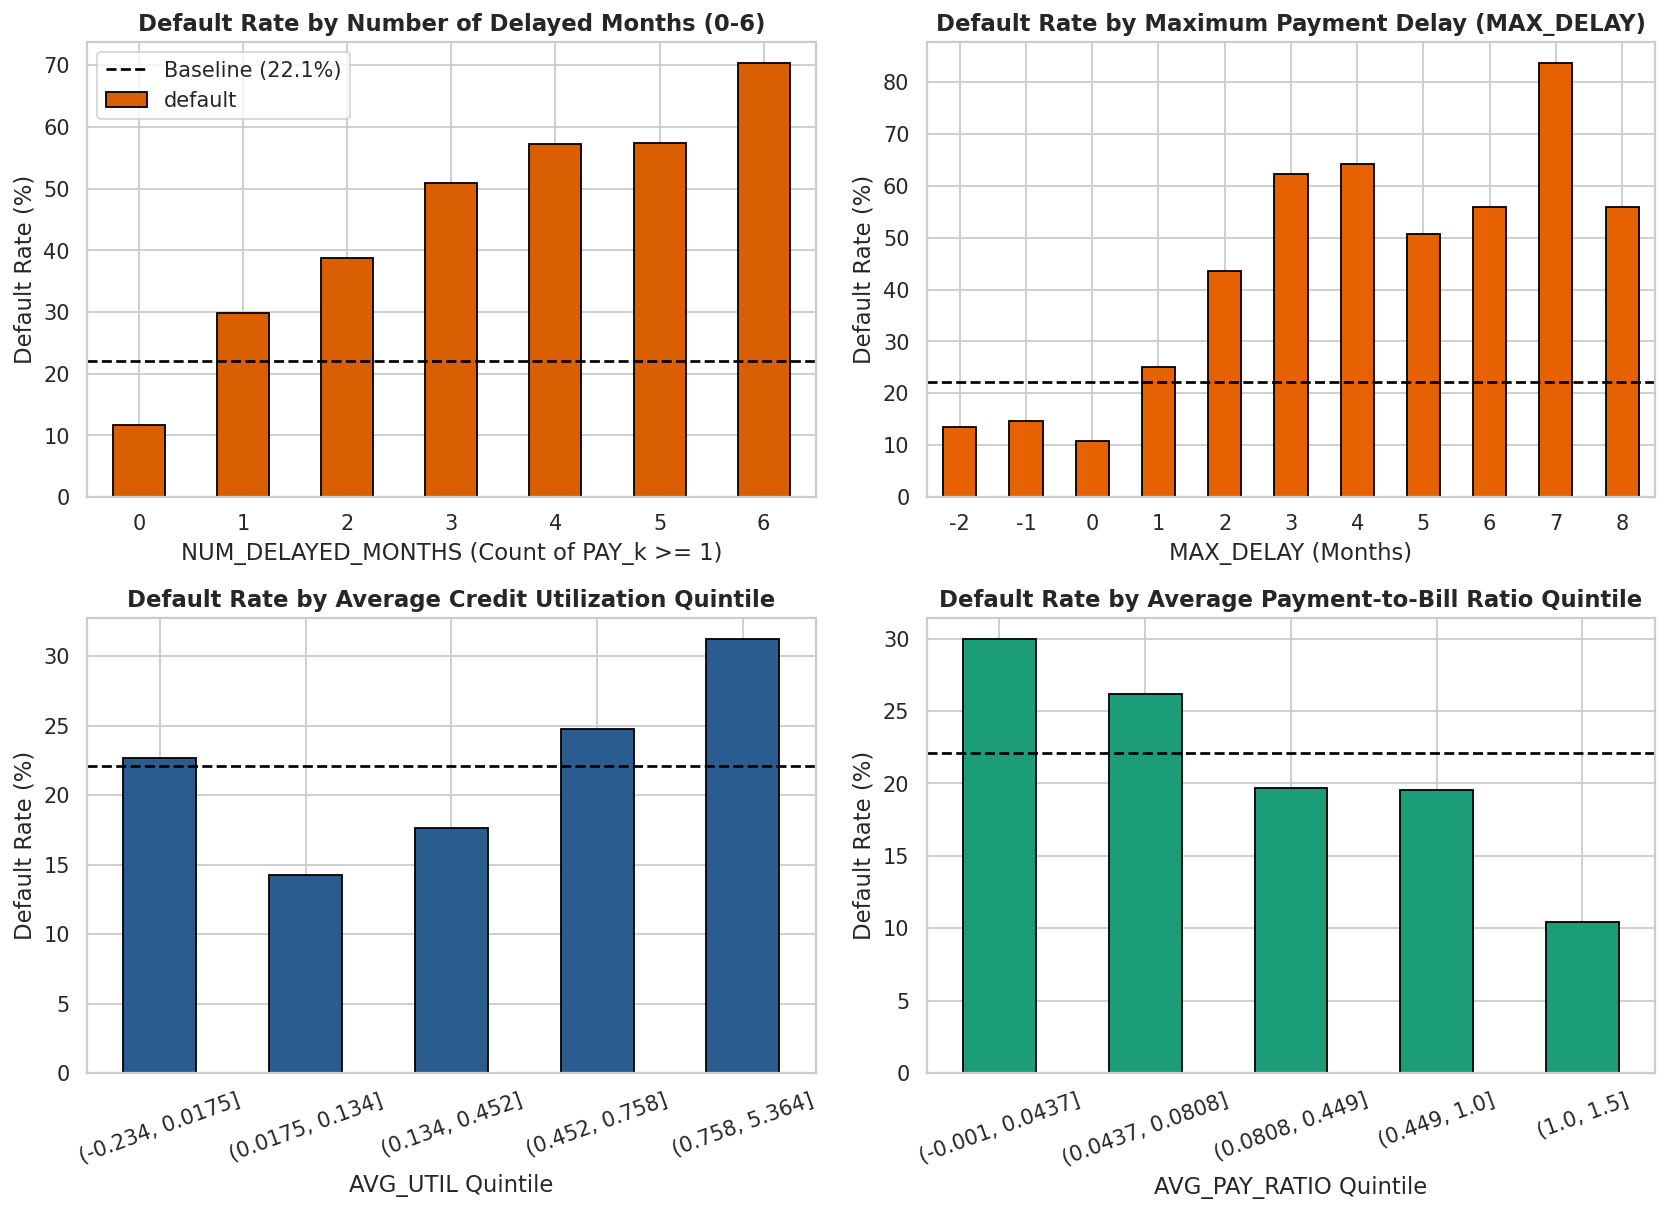

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
overall_rate = df_feat["default"].mean() * 100

# 1. Default rate by NUM_DELAYED_MONTHS (0 to 6)
nd_rate = df_feat.groupby("NUM_DELAYED_MONTHS")["default"].mean() * 100
nd_rate.plot(kind="bar", color="#d95f02", edgecolor="black", ax=axes[0, 0])
axes[0, 0].axhline(overall_rate, color="black", linestyle="--", label=f"Baseline ({overall_rate:.1f}%)")
axes[0, 0].set_title("Default Rate by Number of Delayed Months (0-6)", fontweight="bold")
axes[0, 0].set_xlabel("NUM_DELAYED_MONTHS (Count of PAY_k >= 1)")
axes[0, 0].set_ylabel("Default Rate (%)")
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 0].legend()

# 2. Default rate by MAX_DELAY
md_rate = df_feat.groupby("MAX_DELAY")["default"].mean() * 100
md_rate.plot(kind="bar", color="#e66101", edgecolor="black", ax=axes[0, 1])
axes[0, 1].axhline(overall_rate, color="black", linestyle="--")
axes[0, 1].set_title("Default Rate by Maximum Payment Delay (MAX_DELAY)", fontweight="bold")
axes[0, 1].set_xlabel("MAX_DELAY (Months)")
axes[0, 1].set_ylabel("Default Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3. Default rate by AVG_UTIL Quintiles
util_bins = pd.qcut(df_feat["AVG_UTIL"], q=5, duplicates="drop")
util_rate = df_feat.groupby(util_bins, observed=False)["default"].mean() * 100
util_rate.plot(kind="bar", color="#2b5c8f", edgecolor="black", ax=axes[1, 0])
axes[1, 0].axhline(overall_rate, color="black", linestyle="--")
axes[1, 0].set_title("Default Rate by Average Credit Utilization Quintile", fontweight="bold")
axes[1, 0].set_xlabel("AVG_UTIL Quintile")
axes[1, 0].set_ylabel("Default Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=20)

# 4. Default rate by AVG_PAY_RATIO Quintiles
pr_bins = pd.qcut(df_feat["AVG_PAY_RATIO"], q=5, duplicates="drop")
pr_rate = df_feat.groupby(pr_bins, observed=False)["default"].mean() * 100
pr_rate.plot(kind="bar", color="#1b9e77", edgecolor="black", ax=axes[1, 1])
axes[1, 1].axhline(overall_rate, color="black", linestyle="--")
axes[1, 1].set_title("Default Rate by Average Payment-to-Bill Ratio Quintile", fontweight="bold")
axes[1, 1].set_xlabel("AVG_PAY_RATIO Quintile")
axes[1, 1].set_ylabel("Default Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
fig.savefig(FIG_DIR / "02_engineered_features_vs_default.png")
plt.show()

## 3. Feature Correlation with Target & Feature Retention Policy

We inspect the correlation of all engineered and original features with `default`:
- **`NUM_DELAYED_MONTHS` ($r = 0.398$), `MAX_DELAY` ($r = 0.331$), `PAY_1` ($r = 0.325$), and `AVG_DELAY` ($r = 0.282$)** are the top predictors of default—substantially outperforming any single raw bill or demographic feature!
- **Feature Retention Decision:** We keep the original `PAY_1..6` columns alongside the engineered aggregates (`MAX_DELAY`, `AVG_DELAY`, `NUM_DELAYED_MONTHS`, `EVER_SEVERE_DELAY`, `AVG_UTIL`, `AVG_PAY_RATIO`, `UNPAID_TO_LIMIT`, `LOG_*`, and one-hot encodings) because tree-based models (`RandomForestClassifier`, `XGBClassifier`) exploit nonlinear interactions between recent and historical delinquency, while `LogisticRegression` uses L1/L2 (`saga`) regularization to shrink redundant collinear weights.

Top 15 positively and negatively correlated features with default:


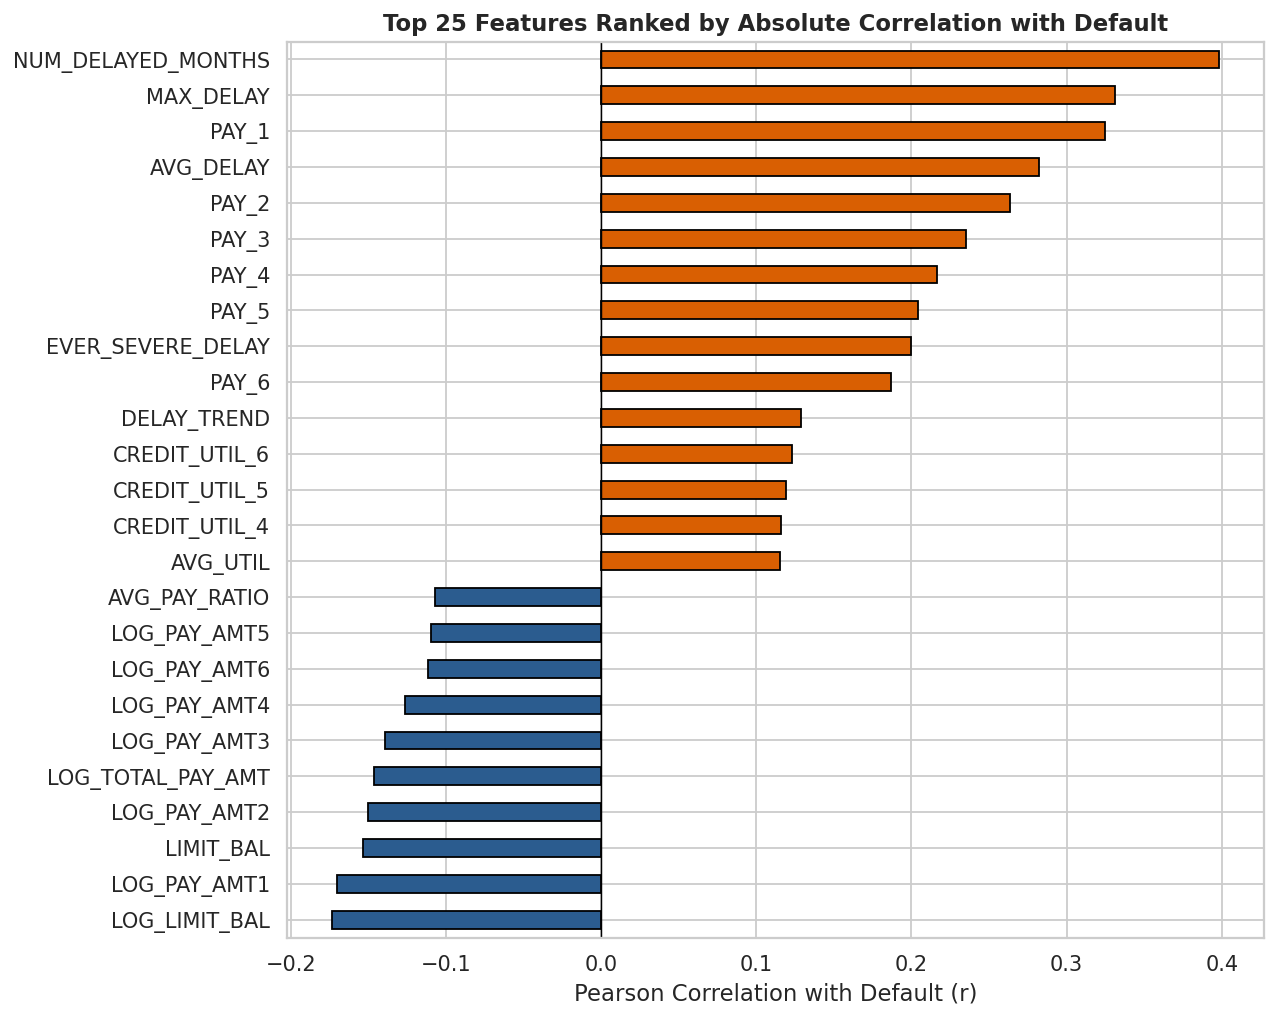

,Pearson_r
NUM_DELAYED_MONTHS,0.3984
MAX_DELAY,0.3310
PAY_1,0.3248
AVG_DELAY,0.2820
PAY_2,0.2636
PAY_3,0.2353
PAY_4,0.2166
PAY_5,0.2041
EVER_SEVERE_DELAY,0.1998
PAY_6,0.1869


In [5]:
target_corr = (
    df_feat.corr()["default"]
    .drop(["default", "RECENT_DELAY"])  # RECENT_DELAY is identical to PAY_1
    .sort_values(key=abs, ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 8))
top25 = target_corr.head(25).sort_values()
colors = ["#d95f02" if v > 0 else "#2b5c8f" for v in top25.values]
top25.plot(kind="barh", color=colors, edgecolor="black", ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Pearson Correlation with Default (r)")
ax.set_title("Top 25 Features Ranked by Absolute Correlation with Default", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "02_top_feature_correlations.png")
plt.show()

# Drop exact duplicate alias RECENT_DELAY (identical to PAY_1) before saving
df_feat = df_feat.drop(columns=["RECENT_DELAY"])

print("Top 15 positively and negatively correlated features with default:")
target_corr.head(15).round(4).to_frame(name="Pearson_r")

In [6]:
# Save engineered dataset to data/processed/features.parquet
feat_path = PROCESSED_DIR / "features.parquet"
df_feat.to_parquet(feat_path, index=False)
print(f"Saved engineered features to {feat_path} ({df_feat.shape[0]:,} rows, {df_feat.shape[1]} columns)")

Saved engineered features to data/processed/features.parquet (30,000 rows, 77 columns)
